# RQ3: Design Choices

This notebook analyses how the characteristics of a model relate to its accuracy and to its energy: its size, its architecture, the numerical precision of its weights and its operating mode.

The process consists of:
1. **Size and Energy per Token**: Relating the energy per generated token to the total and to the active parameters of each model.
2. **Size Categories over Time**: Following the best accuracy of each size category, and when the larger categories had reached it.
3. **Sparsely Activated Models**: Comparing each sparsely activated model with the dense models of its period.
4. **Numerical Precision**: Comparing the 8-bit and 16-bit runs of the Ministral 3 instruct models.
5. **Operating Mode**: Comparing the instruct and reasoning runs of each pair, in three views of the accuracy.
6. **Cost of the Reasoning Mode**: Splitting the difference of intelligence efficiency of each pair into its three factors.
7. **Responses Cut Off**: Measuring the responses that reached the output limit, and their effect on the energy results.
8. **Correlations**: Correlating the characteristics of the model runs with their results.
9. **Predicting Energy**: Predicting the energy per token from the size, and the energy per question from the size and the mode.
10. **Size and Intelligence Efficiency**: Comparing the accuracy, the energy and the correct answers per kJ of the instruct runs of the three size categories.
11. **Instruct Responses at the Limit**: Describing the responses that reached the output limit in the instruct runs with more than 5% of them.
12. **Key Values**: Printing the main values of this notebook.

### Setup & Imports
We load the tables built by `00-dataset.ipynb` and the chart helpers of `common.py`. The 8-bit runs of the Ministral 3 instruct models are loaded too, and are only used in step 4.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy.stats import binomtest

from common import (
    ARCHITECTURE_COLORS,
    CATEGORY_COLORS,
    CATEGORY_ORDER,
    FACTOR_COLORS,
    LOG_TICKS,
    QUESTIONS,
    SCATTER_STYLE,
    contributions,
    factor_handles,
    format_year_axis,
    load_inferences,
    load_model_runs,
    load_questions,
    pareto_front,
    percent_axis,
    plain_log_axis,
    save_chart,
    short_name,
    stacked_contributions,
    with_log_factors,
)

all_runs = with_log_factors(load_model_runs(include_superseded=True))
model_runs = all_runs[all_runs["in_study"]].sort_values(["release_date", "model_run"]).reset_index(drop=True)
questions = load_questions(all_runs)
by_run = {run: table.set_index("question_id").sort_index() for run, table in questions.groupby("model_run")}

instruct = model_runs[model_runs["mode"] == "Instruct"]
reasoning = model_runs[model_runs["mode"] == "Reasoning"]
LAST_DATE = model_runs["release_date"].max()

print(f"Model runs: {len(model_runs)}   instruct: {len(instruct)}   reasoning: {len(reasoning)}   models: {model_runs['model'].nunique()}")
print(f"Runs loaded only for the comparison of precisions: {len(all_runs) - len(model_runs)}")


def compare(run_a, run_b, question_ids=None):
    # Accuracy and energy of run_b against run_a on the same questions. The accuracy is the share of correct
    # responses over all repetitions.
    a, b = by_run[run_a], by_run[run_b]
    if question_ids is not None:
        a, b = a.loc[question_ids], b.loc[question_ids]
    # Exact McNemar test, on the questions that only one of the two runs gets right in most of its repetitions
    right_a, right_b = a["correct"] > 0.5, b["correct"] > 0.5
    only_a, only_b = int((right_a & ~right_b).sum()), int((~right_a & right_b).sum())
    return {
        "questions": len(a),
        "accuracy_a": a["correct"].mean(),
        "accuracy_b": b["correct"].mean(),
        "difference": 100 * (b["correct"].mean() - a["correct"].mean()),
        "energy_ratio": b["gpu_joules_mean"].mean() / a["gpu_joules_mean"].mean(),
        "only_a": only_a,
        "only_b": only_b,
        "p_value": binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0,
    }

Model runs: 53   instruct: 38   reasoning: 15   models: 47
Runs loaded only for the comparison of precisions: 3


### 1. Size and Energy per Token
We relate the GPU energy per generated token of each model to its total parameters and to its active parameters, the ones used to generate each token. In each panel we fit a power law, and report the share of the variation that it explains (R²). The sparsely activated models are labelled in the first panel, and the models more than 25% away from the fit in the second.

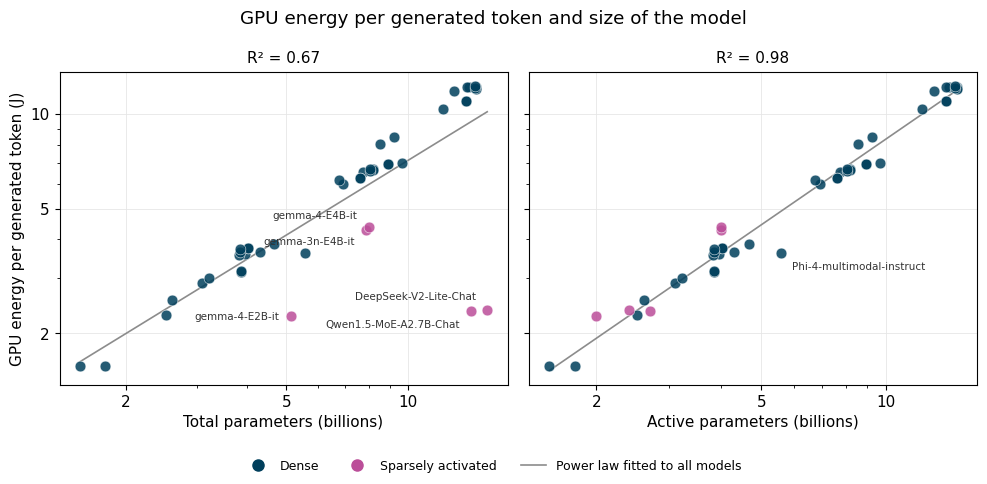

Total parameters (billions): energy per token = 1.15 J x size ^ 0.79   R2 = 0.666
Active parameters (billions): energy per token = 1.03 J x size ^ 0.91   R2 = 0.980


In [2]:
models = model_runs.groupby("model", as_index=False).agg(
    family=("family", "first"),
    category=("category", "first"),
    architecture=("architecture", "first"),
    release_date=("release_date", "first"),
    total_parameters=("total_parameters", "first"),
    activated_parameters=("activated_parameters", "first"),
    gpu_joules_per_generated_token=("gpu_joules_per_generated_token", "mean"),
)


def power_law(x, y):
    # Fit of y = scale * x ^ exponent, with the share of the variance of log y that it explains
    exponent, intercept = np.polyfit(np.log(x), np.log(y), 1)
    residuals = np.log(y) - (intercept + exponent * np.log(x))
    return np.exp(intercept), exponent, 1 - residuals.var() / np.log(y).var()


PANELS = {"total_parameters": "Total parameters (billions)", "activated_parameters": "Active parameters (billions)"}
# Position of the labels, moved apart where the points are close together
LABEL_OFFSETS = {
    "gemma-3n-E4B-it": (-8, -11),
    "gemma-4-E4B-it": (-8, 6),
    "Qwen1.5-MoE-A2.7B-Chat": (-8, -12),
    "DeepSeek-V2-Lite-Chat": (-8, 7),
    "Phi-4-multimodal-instruct": (8, -12),
}
fits = {}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharey=True)
for ax, (column, label) in zip(axes, PANELS.items()):
    scale, exponent, r_squared = fits[column] = power_law(models[column], models["gpu_joules_per_generated_token"])
    x = np.array([models[column].min(), models[column].max()])
    ax.plot(x, scale * x**exponent, color="0.55", linewidth=1.2, zorder=1)
    for architecture, color in ARCHITECTURE_COLORS.items():
        group = models[models["architecture"] == architecture]
        ax.scatter(group[column], group["gpu_joules_per_generated_token"], color=color, edgecolors="w", **SCATTER_STYLE)
    distance = models["gpu_joules_per_generated_token"] / (scale * models[column] ** exponent)
    labelled = models[models["architecture"] == "Sparsely activated"] if column == "total_parameters" else models[(distance - 1).abs() > 0.25]
    for _, model in labelled.iterrows():
        name = model["model"].split("/")[-1]
        offset = LABEL_OFFSETS.get(name, (-8, -3))
        ax.annotate(name, (model[column], model["gpu_joules_per_generated_token"]), xytext=offset, textcoords="offset points", ha="right" if offset[0] < 0 else "left", fontsize=7.5, color="0.2")
    ax.set_xscale("log")
    ax.set_yscale("log")
    plain_log_axis(ax.xaxis)
    plain_log_axis(ax.yaxis)
    ax.set_xlabel(label)
    ax.set_title(f"R² = {r_squared:.2f}", fontsize=11)
axes[0].set_ylabel("GPU energy per generated token (J)")
handles = [Line2D([], [], marker="o", linestyle="", markersize=8, color=color, label=architecture) for architecture, color in ARCHITECTURE_COLORS.items()]
handles.append(Line2D([], [], color="0.55", linewidth=1.2, label="Power law fitted to all models"))
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=9, frameon=False)
fig.suptitle("GPU energy per generated token and size of the model")
plt.tight_layout(rect=(0, 0.07, 1, 1))
save_chart(fig, "rq3-energy-per-token-and-size")
plt.show()

for column, (scale, exponent, r_squared) in fits.items():
    print(f"{PANELS[column]}: energy per token = {scale:.2f} J x size ^ {exponent:.2f}   R2 = {r_squared:.3f}")

### 2. Size Categories over Time
We follow the best accuracy among the instruct runs released so far in each size category. The points are the instruct runs of each category. Two runs are highlighted: the first Tiny/Mobile run above the best Standard/Desktop accuracy of its time, and the most accurate run. The table lists, for each run that raised the best accuracy of the two smaller categories, the first run of each larger category that reached that accuracy, and how many months before (a negative value means that the larger category reached it later).

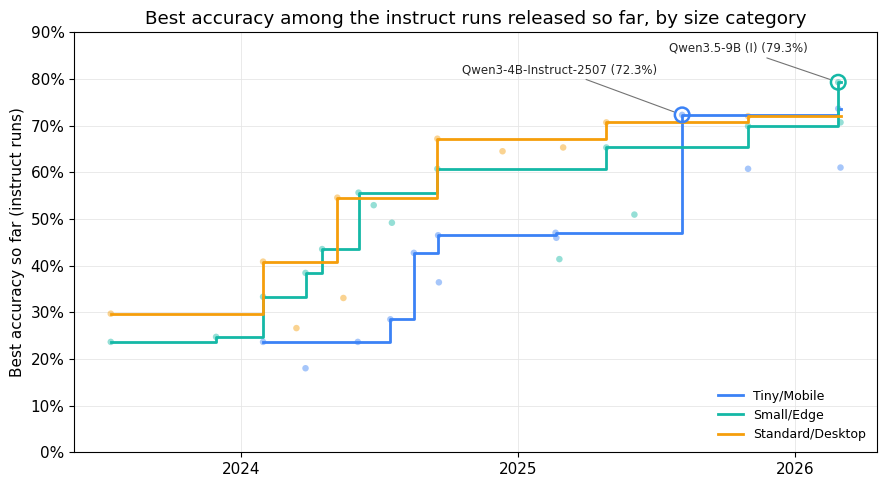

First Tiny/Mobile run above the best Standard/Desktop accuracy of its time: Qwen3-4B-Instruct-2507 (0.723 on 2025-08-05, against 0.707)
Most accurate instruct run: Qwen3.5-9B (I) (0.793, Small/Edge, 2026-02-27)


Released  Accuracy  \
Category    Model run                                                 
Tiny/Mobile Qwen1.5-4B-Chat                    2024-01-30     0.237   
            gemma-2-2b-it                      2024-07-16     0.285   
            Phi-3.5-mini-instruct              2024-08-16     0.427   
            Qwen2.5-3B-Instruct                2024-09-17     0.465   
            Phi-4-mini-instruct                2025-02-19     0.470   
            Qwen3-4B-Instruct-2507             2025-08-05     0.723   
            Qwen3.5-4B (I)                     2026-02-27     0.737   
Small/Edge  Llama-2-7b-chat-hf                 2023-07-13     0.237   
            deepseek-llm-7b-chat               2023-11-29     0.247   
            Qwen1.5-7B-Chat                    2024-01-30     0.333   
            gemma-1.1-7b-it                    2024-03-26     0.384   
            Meta-Llama-3-8B-Instruct           2024-04-17     0.435   
            Qwen2-7B-Instruct                  2024-06-04     0.556   
            Qwen2.5-7B-Instruct                2024-09-16     0.608   
            Qwen3-8B (I)                       2025-04-27     0.653   
            Ministral-3-8B-Instruct-2512-BF16  2025-10-31     0.699   
            Qwen3.5-9B (I)                     2026-02-27     0.793   

                                              Small/Edge: first run at that accuracy  \
Category    Model run                                                                  
Tiny/Mobile Qwen1.5-4B-Chat                                       Llama-2-7b-chat-hf   
            gemma-2-2b-it                                            Qwen1.5-7B-Chat   
            Phi-3.5-mini-instruct                           Meta-Llama-3-8B-Instruct   
            Qwen2.5-3B-Instruct                                    Qwen2-7B-Instruct   
            Phi-4-mini-instruct                                    Qwen2-7B-Instruct   
            Qwen3-4B-Instruct-2507                                    Qwen3.5-9B (I)   
            Qwen3.5-4B (I)                                            Qwen3.5-9B (I)   
Small/Edge  Llama-2-7b-chat-hf                                                         
            deepseek-llm-7b-chat                                                       
            Qwen1.5-7B-Chat                                                            
            gemma-1.1-7b-it                                                            
            Meta-Llama-3-8B-Instruct                                                   
            Qwen2-7B-Instruct                                                          
            Qwen2.5-7B-Instruct                                                        
            Qwen3-8B (I)                                                               
            Ministral-3-8B-Instruct-2512-BF16                                          
            Qwen3.5-9B (I)                                                             

                                              Small/Edge: months before  \
Category    Model run                                                     
Tiny/Mobile Qwen1.5-4B-Chat                                         6.6   
            gemma-2-2b-it                                           5.5   
            Phi-3.5-mini-instruct                                   4.0   
            Qwen2.5-3B-Instruct                                     3.4   
            Phi-4-mini-instruct                                     8.5   
            Qwen3-4B-Instruct-2507                                 -6.8   
            Qwen3.5-4B (I)                                          0.0   
Small/Edge  Llama-2-7b-chat-hf                                            
            deepseek-llm-7b-chat                                          
            Qwen1.5-7B-Chat                                               
            gemma-1.1-7b-it                                               
            Meta-Llama-3-8B-Instruct               

In [3]:
records = {}
fig, ax = plt.subplots(figsize=(9, 5))
for category in CATEGORY_ORDER:
    runs = instruct[instruct["category"] == category]
    best = runs[runs["accuracy"] > runs["accuracy"].cummax().shift(fill_value=-np.inf)].drop_duplicates("release_date", keep="last")
    records[category] = best
    ax.scatter(runs["release_date"], runs["accuracy"], s=22, color=CATEGORY_COLORS[category], alpha=0.45, edgecolors="none", zorder=2)
    ax.step(list(best["release_date"]) + [LAST_DATE], list(best["accuracy"]) + [best["accuracy"].iloc[-1]], where="post", color=CATEGORY_COLORS[category], linewidth=2, label=category, zorder=3)

def best_until(category, date):
    # Best accuracy of the category among the runs released until the date
    earlier = records[category][records[category]["release_date"] <= date]
    return earlier["accuracy"].iloc[-1] if len(earlier) else -np.inf


tiny = records["Tiny/Mobile"]
surpassing = tiny[[run["accuracy"] > best_until("Standard/Desktop", run["release_date"]) for _, run in tiny.iterrows()]].iloc[0]
most_accurate = instruct.loc[instruct["accuracy"].idxmax()]
for run, offset in [(surpassing, (-18, 30)), (most_accurate, (-22, 22))]:
    color = CATEGORY_COLORS[run["category"]]
    ax.scatter(run["release_date"], run["accuracy"], s=110, facecolors="none", edgecolors=color, linewidth=1.8, zorder=4)
    ax.annotate(
        f"{short_name(run['model_run'])} ({run['accuracy']:.1%})",
        (run["release_date"], run["accuracy"]),
        xytext=offset,
        textcoords="offset points",
        ha="right",
        fontsize=8.5,
        color="0.15",
        arrowprops=dict(arrowstyle="-", color="0.45", linewidth=0.8, shrinkA=1, shrinkB=6),
    )
format_year_axis(ax)
ax.set_ylim(0, 0.9)
percent_axis(ax.yaxis)
ax.set_ylabel("Best accuracy so far (instruct runs)")
ax.set_title("Best accuracy among the instruct runs released so far, by size category")
ax.legend(loc="lower right", fontsize=9, frameon=False)
plt.tight_layout()
save_chart(fig, "rq3-best-accuracy-by-size-category")
plt.show()

rows = []
for position, category in enumerate(CATEGORY_ORDER[:-1]):
    for _, run in records[category].iterrows():
        row = {"Category": category, "Model run": short_name(run["model_run"]), "Released": run["release_date"].date(), "Accuracy": round(run["accuracy"], 3)}
        for larger in CATEGORY_ORDER[position + 1:]:
            reached = records[larger][records[larger]["accuracy"] >= run["accuracy"]]
            if reached.empty:
                row[f"{larger}: first run at that accuracy"], row[f"{larger}: months before"] = "none", np.nan
            else:
                first = reached.iloc[0]
                row[f"{larger}: first run at that accuracy"] = short_name(first["model_run"])
                row[f"{larger}: months before"] = round((run["release_date"] - first["release_date"]).days / 30.44, 1)
        rows.append(row)
catching_up = pd.DataFrame(rows)
print(f"First Tiny/Mobile run above the best Standard/Desktop accuracy of its time: {short_name(surpassing['model_run'])} ({surpassing['accuracy']:.3f} on {surpassing['release_date'].date()}, against {best_until('Standard/Desktop', surpassing['release_date']):.3f})")
print(f"Most accurate instruct run: {short_name(most_accurate['model_run'])} ({most_accurate['accuracy']:.3f}, {most_accurate['category']}, {most_accurate['release_date'].date()})")
catching_up.set_index(["Category", "Model run"]).fillna("")

The instruct runs of each size category by release year: number of runs, best and median accuracy, and median GPU energy per question.

In [4]:
by_year = instruct.assign(year=instruct["release_date"].dt.year, category=pd.Categorical(instruct["category"], CATEGORY_ORDER, ordered=True)).groupby(["year", "category"], observed=True).agg(
    runs=("model_run", "size"),
    best_accuracy=("accuracy", "max"),
    median_accuracy=("accuracy", "median"),
    median_joules_per_question=("gpu_joules_per_question", "median"),
)
by_year.round({"best_accuracy": 3, "median_accuracy": 3, "median_joules_per_question": 0})

runs  best_accuracy  median_accuracy  \
year category                                                 
2023 Small/Edge           2          0.247            0.242   
     Standard/Desktop     1          0.297            0.297   
2024 Tiny/Mobile          7          0.465            0.285   
     Small/Edge           7          0.608            0.492   
     Standard/Desktop     6          0.672            0.477   
2025 Tiny/Mobile          4          0.723            0.539   
     Small/Edge           4          0.699            0.581   
     Standard/Desktop     3          0.720            0.707   
2026 Tiny/Mobile          2          0.737            0.673   
     Small/Edge           2          0.793            0.750   

                       median_joules_per_question  
year category                                      
2023 Small/Edge                            1073.0  
     Standard/Desktop                      2491.0  
2024 Tiny/Mobile                            466.0  
     Small/Edge                            1529.0  
     Standard/Desktop                      2158.0  
2025 Tiny/Mobile                           1417.0  
     Small/Edge                            1466.0  
     Standard/Desktop                      3234.0  
2026 Tiny/Mobile                           2217.0  
     Small/Edge                            3748.0

### 3. Sparsely Activated Models
We compare the instruct run of each sparsely activated model with the dense instruct runs released up to six months before or after it. Two groups of dense models are used: those of the same size category (similar total parameters), and those whose size is within 1.5 times the active parameters of the sparse model.

In [5]:
WINDOW = pd.Timedelta(days=183)
dense = instruct[instruct["architecture"] == "Dense"]

rows = []
for _, run in instruct[instruct["architecture"] == "Sparsely activated"].iterrows():
    period = dense[(dense["release_date"] - run["release_date"]).abs() <= WINDOW]
    groups = {
        "Same size category": period[period["category"] == run["category"]],
        "Similar active parameters": period[(period["total_parameters"] / run["activated_parameters"]).between(1 / 1.5, 1.5)],
    }
    for name, group in groups.items():
        rows.append({
            "Sparse model": short_name(run["model_run"]),
            "Total / active parameters (B)": f"{run['total_parameters']:g} / {run['activated_parameters']:g}",
            "Dense models compared": name,
            "Number": len(group),
            "Accuracy": round(run["accuracy"], 3),
            "Median accuracy of the dense models": round(group["accuracy"].median(), 3),
            "Difference (points)": round(100 * (run["accuracy"] - group["accuracy"].median()), 1),
            "Energy per token (ratio)": round(run["gpu_joules_per_generated_token"] / group["gpu_joules_per_generated_token"].median(), 2),
            "Tokens per question (ratio)": round(run["generated_tokens_per_question"] / group["generated_tokens_per_question"].median(), 2),
            "Energy per question (ratio)": round(run["gpu_joules_per_question"] / group["gpu_joules_per_question"].median(), 2),
        })
sparse_table = pd.DataFrame(rows)
sparse_table.set_index(["Sparse model", "Total / active parameters (B)", "Dense models compared"])

Number  \
Sparse model           Total / active parameters (B) Dense models compared               
Qwen1.5-MoE-A2.7B-Chat 14.32 / 2.7                   Same size category              2   
                                                     Similar active parameters       4   
DeepSeek-V2-Lite-Chat  15.71 / 2.4                   Same size category              3   
                                                     Similar active parameters       4   
gemma-3n-E4B-it        7.85 / 4                      Same size category              3   
                                                     Similar active parameters       5   
gemma-4-E2B-it (I)     5.12 / 2                      Same size category              2   
                                                     Similar active parameters       0   
gemma-4-E4B-it (I)     8 / 4                         Same size category              2   
                                                     Similar active parameters       2   

                                                                                Accuracy  \
Sparse model           Total / active parameters (B) Dense models compared                 
Qwen1.5-MoE-A2.7B-Chat 14.32 / 2.7                   Same size category            0.266   
                                                     Similar active parameters     0.266   
DeepSeek-V2-Lite-Chat  15.71 / 2.4                   Same size category            0.331   
                                                     Similar active parameters     0.331   
gemma-3n-E4B-it        7.85 / 4                      Same size category            0.509   
                                                     Similar active parameters     0.509   
gemma-4-E2B-it (I)     5.12 / 2                      Same size category            0.610   
                                                     Similar active parameters     0.610   
gemma-4-E4B-it (I)     8 / 4                         Same size category            0.707   
                                                     Similar active parameters     0.707   

                                                                                Median accuracy of the dense models  \
Sparse model           Total / active parameters (B) Dense models compared                                            
Qwen1.5-MoE-A2.7B-Chat 14.32 / 2.7                   Same size category                                       0.477   
                                                     Similar active parameters                                0.261   
DeepSeek-V2-Lite-Chat  15.71 / 2.4                   Same size category                                       0.546   
                                                     Similar active parameters                                0.325   
gemma-3n-E4B-it        7.85 / 4                      Same size category                                       0.653   
                                                     Similar active parameters                                0.470   
gemma-4-E2B-it (I)     5.12 / 2                      Same size category                                       0.672   
                                                     Similar active parameters                                  NaN   
gemma-4-E4B-it (I)     8 / 4                         Same size category                                       0.746   
                                                     Similar active parameters                                0.672   

                                                                                Difference (points)  \
Sparse model           Total / active parameters (B) Dense models compared                            
Qwen1.5-MoE-A2.7B-Chat 14.32 / 2.7                   Same size category                       -21.1   
                                                     Similar active parameters                  0.5   
DeepSeek-V2-Lite-Chat  15.71 / 2.4                   

We compare each sparsely activated model with the dense instruct runs of its own family released in the six months before it. The difference of accuracy is tested question by question, with the exact McNemar test.

In [6]:
rows = []
for _, run in instruct[instruct["architecture"] == "Sparsely activated"].iterrows():
    earlier = dense[(dense["family"] == run["family"]) & (dense["release_date"] <= run["release_date"]) & (dense["release_date"] >= run["release_date"] - WINDOW)]
    for _, other in earlier.sort_values("total_parameters").iterrows():
        rows.append({
            "Sparse model": short_name(run["model_run"]),
            "Dense model": short_name(other["model_run"]),
            "Parameters of the dense model (B)": other["total_parameters"],
            "Accuracy": round(run["accuracy"], 3),
            "Accuracy of the dense model": round(other["accuracy"], 3),
            "Difference (points)": round(100 * (run["accuracy"] - other["accuracy"]), 1),
            "McNemar p": round(compare(other["model_run"], run["model_run"])["p_value"], 3),
            "Energy per token (ratio)": round(run["gpu_joules_per_generated_token"] / other["gpu_joules_per_generated_token"], 2),
            "Energy per question (ratio)": round(run["gpu_joules_per_question"] / other["gpu_joules_per_question"], 2),
        })
family_table = pd.DataFrame(rows)
family_table.set_index(["Sparse model", "Dense model"])

Parameters of the dense model (B)  \
Sparse model           Dense model                                               
Qwen1.5-MoE-A2.7B-Chat Qwen1.5-4B-Chat                                    3.95   
                       Qwen1.5-7B-Chat                                    7.72   
                       Qwen1.5-14B-Chat                                  14.17   
DeepSeek-V2-Lite-Chat  deepseek-llm-7b-chat                               6.91   
gemma-3n-E4B-it        gemma-3-4b-it                                      4.30   
                       gemma-3-12b-it                                    12.19   

                                             Accuracy  \
Sparse model           Dense model                      
Qwen1.5-MoE-A2.7B-Chat Qwen1.5-4B-Chat          0.266   
                       Qwen1.5-7B-Chat          0.266   
                       Qwen1.5-14B-Chat         0.266   
DeepSeek-V2-Lite-Chat  deepseek-llm-7b-chat     0.331   
gemma-3n-E4B-it        gemma-3-4b-it            0.509   
                       gemma-3-12b-it           0.509   

                                             Accuracy of the dense model  \
Sparse model           Dense model                                         
Qwen1.5-MoE-A2.7B-Chat Qwen1.5-4B-Chat                             0.237   
                       Qwen1.5-7B-Chat                             0.333   
                       Qwen1.5-14B-Chat                            0.409   
DeepSeek-V2-Lite-Chat  deepseek-llm-7b-chat                        0.247   
gemma-3n-E4B-it        gemma-3-4b-it                               0.460   
                       gemma-3-12b-it                              0.653   

                                             Difference (points)  McNemar p  \
Sparse model           Dense model                                            
Qwen1.5-MoE-A2.7B-Chat Qwen1.5-4B-Chat                       3.0      0.348   
                       Qwen1.5-7B-Chat                      -6.7      0.009   
                       Qwen1.5-14B-Chat                    -14.2      0.000   
DeepSeek-V2-Lite-Chat  deepseek-llm-7b-chat                  8.3      0.004   
gemma-3n-E4B-it        gemma-3-4b-it                         5.0      0.836   
                       gemma-3-12b-it                      -14.4      0.000   

                                             Energy per token (ratio)  \
Sparse model           Dense model                                      
Qwen1.5-MoE-A2.7B-Chat Qwen1.5-4B-Chat                           0.66   
                       Qwen1.5-7B-Chat                           0.36   
                       Qwen1.5-14B-Chat                          0.19   
DeepSeek-V2-Lite-Chat  deepseek-llm-7b-chat                      0.40   
gemma-3n-E4B-it        gemma-3-4b-it                             1.18   
                       gemma-3-12b-it                            0.41   

                                             Energy per question (ratio)  
Sparse model           Dense model                                        
Qwen1.5-MoE-A2.7B-Chat Qwen1.5-4B-Chat                              0.95  
                       Qwen1.5-7B-Chat                              0.28  
                       Qwen1.5-14B-Chat                             0.23  
DeepSeek-V2-Lite-Chat  deepseek-llm-7b-chat                         0.68  
gemma-3n-E4B-it        gemma-3-4b-it                                1.48  
                       gemma-3-12b-it                               0.56

We check whether each sparsely activated model is on the Pareto front of accuracy and energy per question: on the front of the model runs released until its own release, and on the front of the whole study. For those that are not on the front of the study, we give the cheapest run of that front that is at least as accurate.

In [7]:
study_front = pareto_front(model_runs, "gpu_joules_per_question", "accuracy")

rows = []
for _, run in instruct[instruct["architecture"] == "Sparsely activated"].iterrows():
    front_at_release = pareto_front(model_runs[model_runs["release_date"] <= run["release_date"]], "gpu_joules_per_question", "accuracy")
    better = study_front[(study_front["accuracy"] >= run["accuracy"]) & (study_front["gpu_joules_per_question"] <= run["gpu_joules_per_question"])]
    cheapest = better.sort_values("gpu_joules_per_question").iloc[0] if len(better) else None
    rows.append({
        "Sparse model": short_name(run["model_run"]),
        "Accuracy": round(run["accuracy"], 3),
        "Energy per question (J)": round(run["gpu_joules_per_question"]),
        "On the front at its release": run["model_run"] in set(front_at_release["model_run"]),
        "On the front of the study": run["model_run"] in set(study_front["model_run"]),
        "Cheapest front run at least as accurate": "" if cheapest is None else f"{short_name(cheapest['model_run'])} ({cheapest['total_parameters']:g}B, {cheapest['accuracy']:.3f}, {cheapest['gpu_joules_per_question']:.0f} J)",
    })
sparse_front = pd.DataFrame(rows)
sparse_front.set_index("Sparse model")

,Accuracy,Energy per question (J),On the front at its release,On the front of the study,Cheapest front run at least as accurate
Sparse model,,,,,
Qwen1.5-MoE-A2.7B-Chat,0.266,444,True,False,"gemma-2-2b-it (2.61B, 0.285, 339 J)"
DeepSeek-V2-Lite-Chat,0.331,591,True,False,"Phi-4-mini-instruct (3.84B, 0.470, 564 J)"
gemma-3n-E4B-it,0.509,1820,False,False,"Qwen3-8B (I) (8.19B, 0.653, 1111 J)"
gemma-4-E2B-it (I),0.610,1306,False,False,"Qwen3-8B (I) (8.19B, 0.653, 1111 J)"
gemma-4-E4B-it (I),0.707,2824,False,False,"Qwen3-14B (I) (14.77B, 0.707, 2131 J)"


### 4. Numerical Precision
We compare the 8-bit runs of the three Ministral 3 instruct models (main execution) with their 16-bit runs (supplementary execution). The difference of accuracy is tested question by question, with the exact McNemar test.

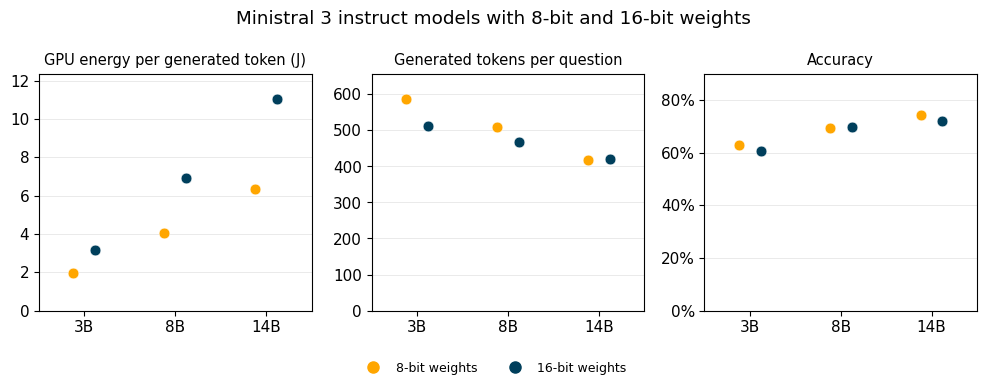

Model,Ministral 3 3B,Ministral 3 8B,Ministral 3 14B
"Energy per token, 8-bit (J)",1.990,4.070,6.340
"Energy per token, 16-bit (J)",3.140,6.910,11.040
Energy per token (16-bit ÷ 8-bit),1.580,1.700,1.740
"Tokens per question, 8-bit",587.000,509.000,418.000
"Tokens per question, 16-bit",511.000,468.000,419.000
Energy per question (16-bit ÷ 8-bit),1.370,1.560,1.750
"Accuracy, 8-bit",0.629,0.694,0.742
"Accuracy, 16-bit",0.608,0.699,0.720
Accuracy difference (points),-2.200,0.500,-2.200
Questions right only with 8-bit,34.000,25.000,21.000


In [8]:
PRECISION_COLORS = {"8-bit": "#ffa600", "16-bit": "#003f5c"}
SIZES = ["3B", "8B", "14B"]
ministral = all_runs[(all_runs["family"] == "Mistral") & (all_runs["mode"] == "Instruct")].copy()
ministral["size"] = ministral["model_run"].str.split("-").str[2]
ministral = ministral.set_index(["size", "precision"])

rows = []
for size in SIZES:
    low, high = ministral.loc[(size, "8-bit")], ministral.loc[(size, "16-bit")]
    paired = compare(low["model_run"], high["model_run"])
    rows.append({
        "Model": f"Ministral 3 {size}",
        "Energy per token, 8-bit (J)": round(low["gpu_joules_per_generated_token"], 2),
        "Energy per token, 16-bit (J)": round(high["gpu_joules_per_generated_token"], 2),
        "Energy per token (16-bit ÷ 8-bit)": round(high["gpu_joules_per_generated_token"] / low["gpu_joules_per_generated_token"], 2),
        "Tokens per question, 8-bit": round(low["generated_tokens_per_question"]),
        "Tokens per question, 16-bit": round(high["generated_tokens_per_question"]),
        "Energy per question (16-bit ÷ 8-bit)": round(high["gpu_joules_per_question"] / low["gpu_joules_per_question"], 2),
        "Accuracy, 8-bit": round(low["accuracy"], 3),
        "Accuracy, 16-bit": round(high["accuracy"], 3),
        "Accuracy difference (points)": round(100 * (high["accuracy"] - low["accuracy"]), 1),
        "Questions right only with 8-bit": paired["only_a"],
        "Questions right only with 16-bit": paired["only_b"],
        "McNemar p": round(paired["p_value"], 3),
    })
precision_table = pd.DataFrame(rows).set_index("Model")

PRECISION_PANELS = {
    "gpu_joules_per_generated_token": "GPU energy per generated token (J)",
    "generated_tokens_per_question": "Generated tokens per question",
    "accuracy": "Accuracy",
}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.8))
positions = np.arange(len(SIZES))
for ax, (column, label) in zip(axes, PRECISION_PANELS.items()):
    for offset, (precision, color) in zip([-0.12, 0.12], PRECISION_COLORS.items()):
        runs = ministral.xs(precision, level="precision").loc[SIZES]
        ax.scatter(positions + offset, runs[column], s=60, color=color, edgecolors="w", linewidth=0.4, zorder=3)
    ax.set_xticks(positions, labels=SIZES)
    ax.set_xlim(-0.5, len(SIZES) - 0.5)
    ax.set_ylim(0, 1.12 * ministral[column].max())
    ax.set_title(label, fontsize=10.5)
    ax.grid(axis="x", visible=False)
axes[2].set_ylim(0, 0.9)
percent_axis(axes[2].yaxis)
handles = [Line2D([], [], marker="o", linestyle="", markersize=8, color=color, label=f"{precision} weights") for precision, color in PRECISION_COLORS.items()]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=9, frameon=False)
fig.suptitle("Ministral 3 instruct models with 8-bit and 16-bit weights")
plt.tight_layout(rect=(0, 0.08, 1, 1))
save_chart(fig, "rq3-precision")
plt.show()

precision_table.T

### 5. Operating Mode
We compare the instruct and the reasoning run of each of the 12 pairs of the same release and size: six dual-mode models, which use the same weights in both modes, and six pairs of separate variants. The difference of accuracy is given in three views:

1. **As recorded**: the accuracy of each run on the whole benchmark.
2. **Strict**: every response that reached the output limit counts as wrong, in both runs.
3. **Finished questions**: only the questions whose reasoning response never reached the output limit.

The differences of accuracy of the first and third views are tested question by question, with the exact McNemar test.

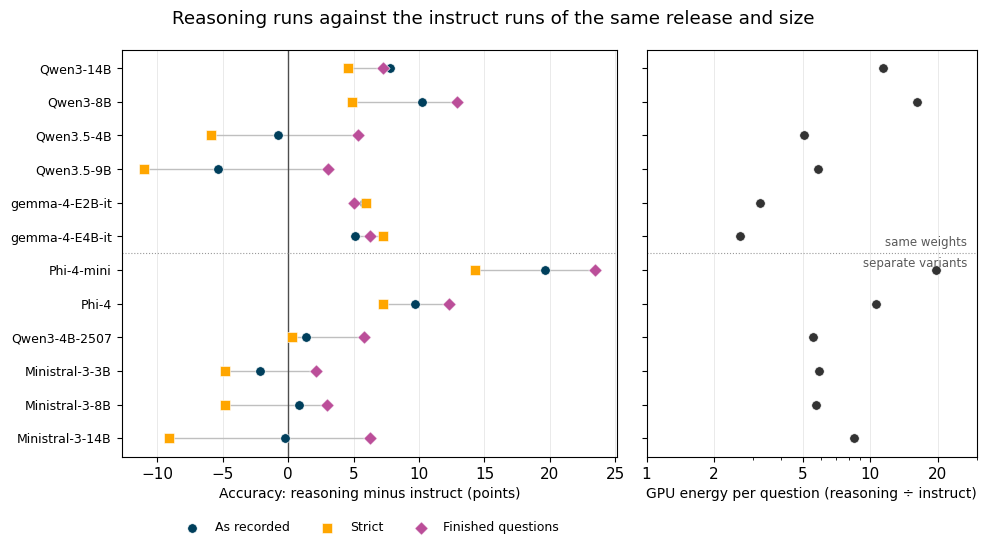

accuracy_instruct  accuracy_reasoning  \
weights           pair                                                     
Same weights      Qwen3-14B                    0.707               0.785   
                  Qwen3-8B                     0.653               0.755   
                  Qwen3.5-4B                   0.737               0.728   
                  Qwen3.5-9B                   0.793               0.739   
                  gemma-4-E2B-it               0.610               0.668   
                  gemma-4-E4B-it               0.707               0.758   
Separate variants Phi-4-mini                   0.470               0.667   
                  Phi-4                        0.645               0.742   
                  Qwen3-4B-2507                0.723               0.737   
                  Ministral-3-3B               0.608               0.586   
                  Ministral-3-8B               0.699               0.707   
                  Ministral-3-14B              0.720               0.718   

                                   as_recorded  p_value  strict  \
weights           pair                                            
Same weights      Qwen3-14B                7.8    0.001     4.6   
                  Qwen3-8B                10.2    0.000     4.8   
                  Qwen3.5-4B              -0.8    0.644    -5.9   
                  Qwen3.5-9B              -5.4    0.007   -11.0   
                  gemma-4-E2B-it           5.8    0.015     5.9   
                  gemma-4-E4B-it           5.1    0.023     7.3   
Separate variants Phi-4-mini              19.6    0.000    14.2   
                  Phi-4                    9.7    0.001     7.3   
                  Qwen3-4B-2507            1.3    0.519     0.3   
                  Ministral-3-3B          -2.2    0.555    -4.8   
                  Ministral-3-8B           0.8    0.832    -4.8   
                  Ministral-3-14B         -0.3    1.000    -9.1   

                                   finished_questions  finished  \
weights           pair                                            
Same weights      Qwen3-14B                       328       7.2   
                  Qwen3-8B                        317      12.9   
                  Qwen3.5-4B                      262       5.3   
                  Qwen3.5-9B                      263       3.0   
                  gemma-4-E2B-it                  347       5.0   
                  gemma-4-E4B-it                  366       6.3   
Separate variants Phi-4-mini                      300      23.4   
                  Phi-4                           341      12.3   
                  Qwen3-4B-2507                   310       5.8   
                  Ministral-3-3B                  288       2.1   
                  Ministral-3-8B                  304       3.0   
                  Ministral-3-14B                 280       6.2   

                                   finished_p_value  common  energy_ratio  \
weights           pair                                                      
Same weights      Qwen3-14B                   0.001     4.0          11.4   
                  Qwen3-8B                    0.000     8.4          16.2   
                  Qwen3.5-4B                  0.007     6.2           5.0   
                  Qwen3.5-9B                  0.039     1.7           5.8   
                  gemma-4-E2B-it              0.126     5.4           3.2   
                  gemma-4-E4B-it              0.004     2.8           2.6   
Separate variants Phi-4-mini                  0.000    16.8          19.6   
                  Phi-4                       0.000     0.0          10.6   
                  Qwen3-4B-2507               0.004     4.5           5.6   
                  Ministral-3-3B              0.545     3.9           5.9   
                  Ministral-3-8B              0.321     3.4           5.7   
                  Ministral-3-14B             0.027     1.7           8.5   

             

In [9]:
VARIANT_PAIRS = {
    "Phi-4-mini": ("microsoft/Phi-4-mini-instruct", "microsoft/Phi-4-mini-reasoning"),
    "Phi-4": ("microsoft/phi-4", "microsoft/Phi-4-reasoning"),
    "Qwen3-4B-2507": ("Qwen/Qwen3-4B-Instruct-2507", "Qwen/Qwen3-4B-Thinking-2507"),
    "Ministral-3-3B": ("mistralai/Ministral-3-3B-Instruct-2512-BF16", "mistralai/Ministral-3-3B-Reasoning-2512"),
    "Ministral-3-8B": ("mistralai/Ministral-3-8B-Instruct-2512-BF16", "mistralai/Ministral-3-8B-Reasoning-2512"),
    "Ministral-3-14B": ("mistralai/Ministral-3-14B-Instruct-2512-BF16", "mistralai/Ministral-3-14B-Reasoning-2512"),
}

pairs = []
for model, runs in model_runs[model_runs["dual_mode"]].groupby("model", sort=False):
    modes = runs.set_index("mode")["model_run"]
    pairs.append({"pair": model.split("/")[-1], "weights": "Same weights", "instruct": modes["Instruct"], "reasoning": modes["Reasoning"]})
for name, (instruct_run, reasoning_run) in VARIANT_PAIRS.items():
    pairs.append({"pair": name, "weights": "Separate variants", "instruct": instruct_run, "reasoning": reasoning_run})
pairs = pd.DataFrame(pairs)

# Questions on which no reasoning run reached the output limit, in any repetition
reasoning_questions = questions[questions["model_run"].isin(reasoning["model_run"])]
never_truncated = reasoning_questions.groupby("question_id")["truncated"].max() == 0
common_questions = never_truncated[never_truncated].index

values = model_runs.set_index("model_run")
rows = []
for _, pair in pairs.iterrows():
    instruct_run, reasoning_run = values.loc[pair["instruct"]], values.loc[pair["reasoning"]]
    finished = by_run[pair["reasoning"]].index[by_run[pair["reasoning"]]["truncated"] == 0]
    whole = compare(pair["instruct"], pair["reasoning"])
    on_finished = compare(pair["instruct"], pair["reasoning"], finished)
    on_common = compare(pair["instruct"], pair["reasoning"], common_questions)
    rows.append({
        "pair": pair["pair"],
        "weights": pair["weights"],
        "accuracy_instruct": instruct_run["accuracy"],
        "accuracy_reasoning": reasoning_run["accuracy"],
        "as_recorded": 100 * (reasoning_run["accuracy"] - instruct_run["accuracy"]),
        "p_value": whole["p_value"],
        "strict": 100 * (reasoning_run["strict_accuracy"] - instruct_run["strict_accuracy"]),
        "finished_questions": on_finished["questions"],
        "finished": on_finished["difference"],
        "finished_p_value": on_finished["p_value"],
        "common": on_common["difference"],
        "energy_ratio": reasoning_run["gpu_joules_per_question"] / instruct_run["gpu_joules_per_question"],
        "tokens_ratio": reasoning_run["generated_tokens_per_question"] / instruct_run["generated_tokens_per_question"],
        "energy_per_token_ratio": reasoning_run["gpu_joules_per_generated_token"] / instruct_run["gpu_joules_per_generated_token"],
        "efficiency_ratio": reasoning_run["correct_answers_per_kj"] / instruct_run["correct_answers_per_kj"],
    })
mode_table = pd.DataFrame(rows)

VIEWS = {"as_recorded": ("As recorded", "o", "#003f5c"), "strict": ("Strict", "s", "#ffa600"), "finished": ("Finished questions", "D", "#bb4e99")}
positions = np.arange(len(mode_table))[::-1]

fig, axes = plt.subplots(1, 2, figsize=(10, 5.6), sharey=True, gridspec_kw={"width_ratios": [1.5, 1]})
view_columns = list(VIEWS)
axes[0].hlines(positions, mode_table[view_columns].min(axis=1), mode_table[view_columns].max(axis=1), color="0.75", linewidth=1, zorder=1)
for column, (label, marker, color) in VIEWS.items():
    axes[0].scatter(mode_table[column], positions, marker=marker, s=46, color=color, edgecolors="w", linewidth=0.4, zorder=3, label=label)
axes[0].axvline(0, color="0.3", linewidth=1)
axes[0].set_xlabel("Accuracy: reasoning minus instruct (points)", fontsize=10)
axes[0].set_yticks(positions, labels=mode_table["pair"], fontsize=9)

axes[1].scatter(mode_table["energy_ratio"], positions, s=46, color="0.2", edgecolors="w", linewidth=0.4, zorder=3)
axes[1].set_xscale("log")
plain_log_axis(axes[1].xaxis)
axes[1].set_xlim(1, 30)
axes[1].set_xlabel("GPU energy per question (reasoning ÷ instruct)", fontsize=10)

# Line and labels separating the two kinds of pair
boundary = positions[(mode_table["weights"] == "Same weights").sum() - 1] - 0.5
for ax in axes:
    ax.axhline(boundary, color="0.6", linewidth=0.8, linestyle=":")
    ax.grid(axis="y", visible=False)
axes[1].text(0.97, boundary + 0.12, "same weights", transform=axes[1].get_yaxis_transform(), ha="right", va="bottom", fontsize=8.5, color="0.35")
axes[1].text(0.97, boundary - 0.12, "separate variants", transform=axes[1].get_yaxis_transform(), ha="right", va="top", fontsize=8.5, color="0.35")

axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=9, frameon=False)
fig.suptitle("Reasoning runs against the instruct runs of the same release and size")
plt.tight_layout()
save_chart(fig, "rq3-operating-mode")
plt.show()

mode_table.set_index(["weights", "pair"]).round({"accuracy_instruct": 3, "accuracy_reasoning": 3, "as_recorded": 1, "p_value": 3, "strict": 1, "finished": 1, "finished_p_value": 3, "common": 1, "energy_ratio": 1, "tokens_ratio": 1, "energy_per_token_ratio": 2, "efficiency_ratio": 3})

In [10]:
print(f"Questions on which no reasoning run reached the output limit: {len(common_questions)} of {QUESTIONS}")
print(f"Finished questions per pair: {mode_table['finished_questions'].min()} to {mode_table['finished_questions'].max()}")
for column, (label, _, _) in VIEWS.items():
    print(f"{label}: reasoning more accurate in {(mode_table[column] > 0).sum()} of {len(mode_table)} pairs, median {mode_table[column].median():+.1f} points")
print(f"Common questions: reasoning more accurate in {(mode_table['common'] > 0).sum()} of {len(mode_table)} pairs, median {mode_table['common'].median():+.1f} points")
print(f"Pairs with a difference of accuracy at p < 0.05 (McNemar): {(mode_table['p_value'] < 0.05).sum()} as recorded, {(mode_table['finished_p_value'] < 0.05).sum()} on the finished questions")
print(f"GPU energy per question, reasoning ÷ instruct: {mode_table['energy_ratio'].min():.1f} to {mode_table['energy_ratio'].max():.1f} times (median {mode_table['energy_ratio'].median():.1f})")
print(f"Accuracy of the instruct runs on the common questions: {np.mean([by_run[run].loc[common_questions, 'correct'].mean() for run in instruct['model_run']]):.3f}; on the other questions: {np.mean([by_run[run].drop(common_questions)['correct'].mean() for run in instruct['model_run']]):.3f}")

Questions on which no reasoning run reached the output limit: 178 of 372
Finished questions per pair: 262 to 366
As recorded: reasoning more accurate in 8 of 12 pairs, median +3.2 points
Strict: reasoning more accurate in 7 of 12 pairs, median +2.4 points
Finished questions: reasoning more accurate in 12 of 12 pairs, median +6.0 points
Common questions: reasoning more accurate in 11 of 12 pairs, median +4.0 points
Pairs with a difference of accuracy at p < 0.05 (McNemar): 7 as recorded, 9 on the finished questions
GPU energy per question, reasoning ÷ instruct: 2.6 to 19.6 times (median 5.9)
Accuracy of the instruct runs on the common questions: 0.644; on the other questions: 0.348


### 6. Cost of the Reasoning Mode
We split the difference of intelligence efficiency between the instruct and the reasoning run of each pair into the contributions of its three factors: accuracy, response length and energy per token.

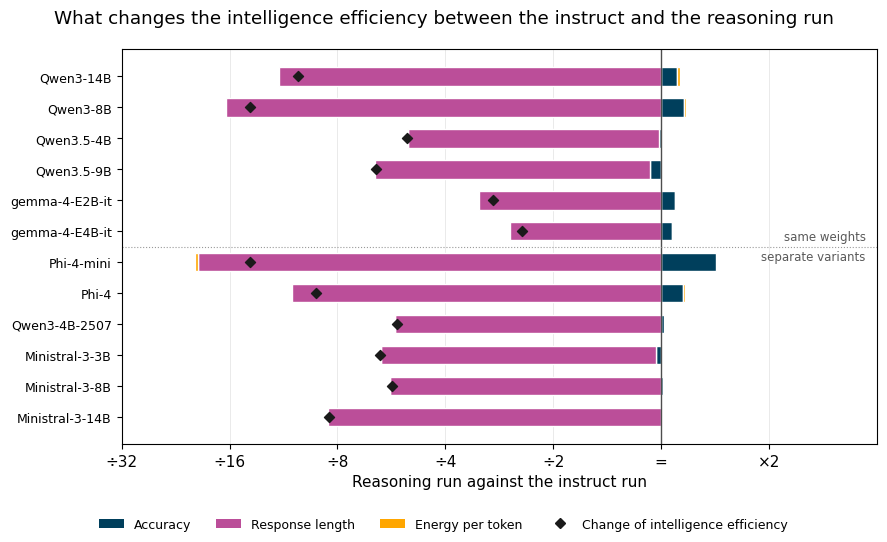

Accuracy  Response length  \
weights           pair                                         
Same weights      Qwen3-14B           1.105            0.086   
                  Qwen3-8B            1.156            0.061   
                  Qwen3.5-4B          0.989            0.198   
                  Qwen3.5-9B          0.932            0.171   
                  gemma-4-E2B-it      1.090            0.309   
                  gemma-4-E4B-it      1.072            0.378   
Separate variants Phi-4-mini          1.422            0.051   
                  Phi-4               1.150            0.093   
                  Qwen3-4B-2507       1.019            0.181   
                  Ministral-3-3B      0.965            0.171   
                  Ministral-3-8B      1.012            0.175   
                  Ministral-3-14B     1.002            0.118   

                                   Energy per token    Net  
weights           pair                                      
Same weights      Qwen3-14B                   1.022  0.097  
                  Qwen3-8B                    1.014  0.072  
                  Qwen3.5-4B                  0.999  0.196  
                  Qwen3.5-9B                  1.004  0.160  
                  gemma-4-E2B-it              1.007  0.339  
                  gemma-4-E4B-it              1.007  0.408  
Separate variants Phi-4-mini                  0.981  0.071  
                  Phi-4                       1.015  0.109  
                  Qwen3-4B-2507               0.995  0.183  
                  Ministral-3-3B              0.995  0.164  
                  Ministral-3-8B              0.999  0.177  
                  Ministral-3-14B             1.003  0.119

In [11]:
rows = []
for _, pair in pairs.iterrows():
    rows.append({"pair": pair["pair"], "weights": pair["weights"], **contributions(values.loc[pair["instruct"]], values.loc[pair["reasoning"]])})
mode_factors = pd.DataFrame(rows)
assert np.allclose(mode_factors[list(FACTOR_COLORS)].sum(axis=1), mode_factors["Net"])

MODE_TICKS = [1 / 32, 1 / 16] + LOG_TICKS[:5]
fig, ax = plt.subplots(figsize=(9, 5.4))
table = mode_factors.iloc[::-1].reset_index(drop=True)
bar_positions = stacked_contributions(ax, table, horizontal=True)
ax.set_xticks(np.log(MODE_TICKS), labels=["÷32", "÷16", "÷8", "÷4", "÷2", "=", "×2"])
ax.set_xlim(np.log(1 / 32), np.log(4))
ax.set_yticks(bar_positions, labels=table["pair"], fontsize=9)
boundary = (table["weights"] == "Separate variants").sum() - 0.5
ax.axhline(boundary, color="0.6", linewidth=0.8, linestyle=":")
ax.text(0.985, boundary + 0.12, "same weights", transform=ax.get_yaxis_transform(), ha="right", va="bottom", fontsize=8.5, color="0.35")
ax.text(0.985, boundary - 0.12, "separate variants", transform=ax.get_yaxis_transform(), ha="right", va="top", fontsize=8.5, color="0.35")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Reasoning run against the instruct run")
fig.suptitle("What changes the intelligence efficiency between the instruct and the reasoning run")
fig.legend(handles=factor_handles(), loc="lower center", ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
save_chart(fig, "rq3-operating-mode-decomposition")
plt.show()

mode_factor_table = mode_factors[["weights", "pair"]].copy()
for factor in list(FACTOR_COLORS) + ["Net"]:
    mode_factor_table[factor] = np.exp(mode_factors[factor]).round(3)
mode_factor_table.set_index(["weights", "pair"])

### 7. Responses Cut Off
We measure, for each model run, the responses that reached the output limit (2,048 generated tokens, plus 4,096 for reasoning models), those that were cut off while the model was still reasoning, and the share of the GPU energy of the run that they hold, each as the median of the repetitions of the run. We also count the reasoning responses without a closed reasoning block, which were either cut off or written without the delimiters. The table lists the reasoning runs and the instruct runs with more than 5% of responses at the limit.

In [12]:
inferences = load_inferences(model_runs)
at_limit = inferences.groupby(["model_run", "repetition"]).apply(
    lambda run: pd.Series({
        "at_limit": 100 * run["truncated"].mean(),
        "cut_off_reasoning": 100 * run["cut_off_reasoning"].mean(),
        "energy_at_limit": 100 * run.loc[run["truncated"], "gpu_joules"].sum() / run["gpu_joules"].sum(),
    }),
    include_groups=False,
).groupby("model_run").median()
at_limit = model_runs[["model_run", "category", "mode", "accuracy", "strict_accuracy"]].merge(at_limit, left_on="model_run", right_index=True)

reasoning_responses = inferences[inferences["model_run"].isin(model_runs.loc[model_runs["mode"] == "Reasoning", "model_run"])]
without_block = reasoning_responses[~reasoning_responses["reasoning_closed"]]
print(f"Reasoning responses without a closed reasoning block: {len(without_block)} of {len(reasoning_responses)}   cut off at the limit: {without_block['truncated'].sum()}   finished without the delimiters: {(~without_block['truncated']).sum()}")

cut_off_table = at_limit[(at_limit["mode"] == "Reasoning") | (at_limit["at_limit"] > 5)].sort_values(["mode", "at_limit"], ascending=[False, False])
cut_off_table = cut_off_table.assign(model_run=cut_off_table["model_run"].map(short_name)).set_index(["mode", "model_run"])
cut_off_table.round({"accuracy": 3, "strict_accuracy": 3, "at_limit": 1, "cut_off_reasoning": 1, "energy_at_limit": 1})

Reasoning responses without a closed reasoning block: 9419 of 55800   cut off at the limit: 7959   finished without the delimiters: 1460


category  accuracy  \
mode      model_run                                                       
Reasoning Qwen3.5-4B (R)                          Tiny/Mobile     0.728   
          Qwen3.5-9B (R)                           Small/Edge     0.739   
          Ministral-3-14B-Reasoning-2512     Standard/Desktop     0.718   
          Ministral-3-3B-Reasoning-2512           Tiny/Mobile     0.586   
          DeepSeek-R1-Distill-Qwen-1.5B           Tiny/Mobile     0.392   
          Phi-4-mini-reasoning                    Tiny/Mobile     0.667   
          DeepSeek-R1-0528-Qwen3-8B                Small/Edge     0.699   
          Ministral-3-8B-Reasoning-2512            Small/Edge     0.707   
          Qwen3-4B-Thinking-2507                  Tiny/Mobile     0.737   
          Qwen3-8B (R)                             Small/Edge     0.755   
          DeepSeek-R1-Distill-Qwen-14B       Standard/Desktop     0.755   
          Qwen3-14B (R)                      Standard/Desktop     0.785   
          Phi-4-reasoning                    Standard/Desktop     0.742   
          gemma-4-E2B-it (R)                      Tiny/Mobile     0.668   
          gemma-4-E4B-it (R)                       Small/Edge     0.758   
Instruct  Qwen3.5-4B (I)                          Tiny/Mobile     0.737   
          Ministral-3-3B-Instruct-2512-BF16       Tiny/Mobile     0.608   
          Qwen3-4B-Instruct-2507                  Tiny/Mobile     0.723   
          Qwen3.5-9B (I)                           Small/Edge     0.793   
          Ministral-3-8B-Instruct-2512-BF16        Small/Edge     0.699   
          gemma-4-E4B-it (I)                       Small/Edge     0.707   

                                             strict_accuracy  at_limit  \
mode      model_run                                                      
Reasoning Qwen3.5-4B (R)                               0.637      29.6   
          Qwen3.5-9B (R)                               0.651      29.3   
          Ministral-3-14B-Reasoning-2512               0.621      24.7   
          Ministral-3-3B-Reasoning-2512                0.530      22.6   
          DeepSeek-R1-Distill-Qwen-1.5B                0.331      20.7   
          Phi-4-mini-reasoning                         0.613      19.4   
          DeepSeek-R1-0528-Qwen3-8B                    0.656      19.1   
          Ministral-3-8B-Reasoning-2512                0.634      18.3   
          Qwen3-4B-Thinking-2507                       0.691      16.7   
          Qwen3-8B (R)                                 0.702      14.8   
          DeepSeek-R1-Distill-Qwen-14B                 0.739       9.1   
          Qwen3-14B (R)                                0.753       8.9   
          Phi-4-reasoning                              0.718       8.3   
          gemma-4-E2B-it (R)                           0.664       1.7   
          gemma-4-E4B-it (R)                           0.758       1.6   
Instruct  Qwen3.5-4B (I)                               0.696      15.1   
          Ministral-3-3B-Instruct-2512-BF16            0.578      11.0   
          Qwen3-4B-Instruct-2507                       0.688      10.5   
          Qwen3.5-9B (I)                               0.761      10.2   
          Ministral-3-8B-Instruct-2512-BF16            0.683       6.7   
          gemma-4-E4B-it (I)                           0.685       5.9   

                                             cut_off_reasoning  \
mode      model_run                                              
Reasoning Qwen3.5-4B (R)                                  22.8   
          Qwen3.5-9B (R)                                  22.8   
          Ministral-3-14B-Reasoning-2512                  21.2   
          Ministral-3-3B-Reasoning-2512                   22.6   
          DeepSeek-R1-Distill-Qwen-1.5B                   19.1   
          Phi-4-mini-reasoning                            18.0   
          DeepSeek-R1-0528-Qwen3-8B                       18.0   
          Ministral-3-8B-Reaso

We check that the energy results do not depend on how these responses are scored, by repeating them with the strict accuracy: the ranking by correct answers per kJ, the Pareto front and the energy per correct answer of the two modes.

In [13]:
strict = model_runs.assign(
    strict_correct_answers_per_kj=1000 * model_runs["strict_accuracy"] / model_runs["gpu_joules_per_question"],
    strict_joules_per_correct_answer=model_runs["gpu_joules_per_question"] / model_runs["strict_accuracy"],
)
rank_change = (strict["correct_answers_per_kj"].rank(ascending=False) - strict["strict_correct_answers_per_kj"].rank(ascending=False)).abs()
front = pareto_front(model_runs, "gpu_joules_per_question", "accuracy")
strict_front = pareto_front(model_runs, "gpu_joules_per_question", "strict_accuracy")
by_mode = strict.groupby("mode")[["gpu_joules_per_correct_answer", "strict_joules_per_correct_answer"]].median()

print(f"Largest change of position in the ranking by correct answers per kJ: {rank_change.max():.0f}; model runs that change position: {(rank_change > 0).sum()}")
print(f"Pareto front as recorded: {len(front)} runs ({(front['mode'] == 'Reasoning').sum()} reasoning); with the strict accuracy: {len(strict_front)} runs ({(strict_front['mode'] == 'Reasoning').sum()} reasoning)")
print(f"Runs on only one of the two fronts: {sorted(short_name(run) for run in set(front['model_run']) ^ set(strict_front['model_run']))}")
ratios = by_mode.loc["Reasoning"] / by_mode.loc["Instruct"]
print(f"Median GPU energy per correct answer, reasoning ÷ instruct: {ratios['gpu_joules_per_correct_answer']:.1f} as recorded, {ratios['strict_joules_per_correct_answer']:.1f} with the strict accuracy")

Largest change of position in the ranking by correct answers per kJ: 2; model runs that change position: 13
Pareto front as recorded: 9 runs (0 reasoning); with the strict accuracy: 8 runs (0 reasoning)
Runs on only one of the two fronts: ['Ministral-3-14B-Instruct-2512-BF16', 'Qwen3-4B-Instruct-2507', 'Qwen3.5-4B (I)']
Median GPU energy per correct answer, reasoning ÷ instruct: 8.8 as recorded, 9.3 with the strict accuracy


### 8. Correlations
We compute the rank correlation (Spearman) between the characteristics of the model runs and their results. The energy is the GPU energy, and the tokens are the generated tokens.

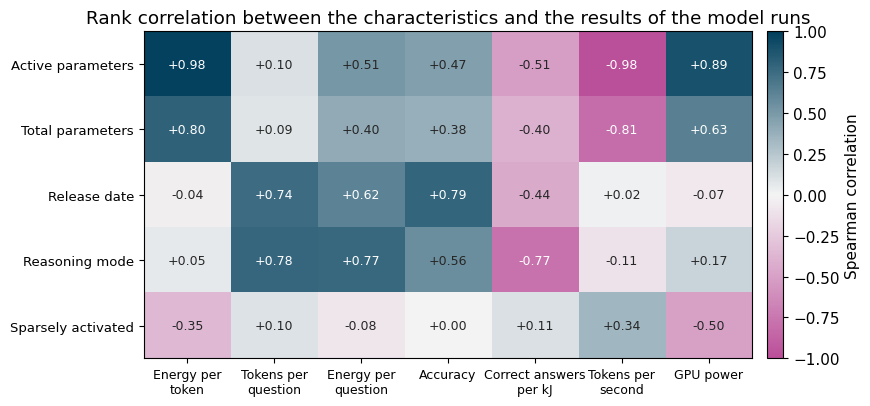

,Energy per token,Tokens per question,Energy per question,Accuracy,Correct answers per kJ,Tokens per second,GPU power
Active parameters,0.98,0.10,0.51,0.47,-0.51,-0.98,0.89
Total parameters,0.80,0.09,0.40,0.38,-0.40,-0.81,0.63
Release date,-0.04,0.74,0.62,0.79,-0.44,0.02,-0.07
Reasoning mode,0.05,0.78,0.77,0.56,-0.77,-0.11,0.17
Sparsely activated,-0.35,0.10,-0.08,0.00,0.11,0.34,-0.50


In [14]:
CHARACTERISTICS = {
    "Active parameters": model_runs["activated_parameters"],
    "Total parameters": model_runs["total_parameters"],
    "Release date": model_runs["release_date"].map(pd.Timestamp.toordinal),
    "Reasoning mode": (model_runs["mode"] == "Reasoning").astype(int),
    "Sparsely activated": (model_runs["architecture"] == "Sparsely activated").astype(int),
}
RESULTS = {
    "Energy per\ntoken": model_runs["gpu_joules_per_generated_token"],
    "Tokens per\nquestion": model_runs["generated_tokens_per_question"],
    "Energy per\nquestion": model_runs["gpu_joules_per_question"],
    "Accuracy": model_runs["accuracy"],
    "Correct answers\nper kJ": model_runs["correct_answers_per_kj"],
    "Tokens per\nsecond": model_runs["decode_tokens_per_second"],
    "GPU power": model_runs["gpu_power_watts"],
}
correlations = pd.DataFrame({result: [values_x.corr(values_y, method="spearman") for values_x in CHARACTERISTICS.values()] for result, values_y in RESULTS.items()}, index=list(CHARACTERISTICS))

colormap = LinearSegmentedColormap.from_list("correlation", ["#bb4e99", "#f4f4f4", "#003f5c"])
fig, ax = plt.subplots(figsize=(9, 4.2))
mesh = ax.imshow(correlations, cmap=colormap, vmin=-1, vmax=1, aspect="auto")
for row in range(correlations.shape[0]):
    for column in range(correlations.shape[1]):
        value = correlations.iat[row, column]
        ax.text(column, row, f"{value:+.2f}", ha="center", va="center", fontsize=9, color="w" if abs(value) > 0.6 else "0.15")
ax.set_xticks(range(correlations.shape[1]), labels=correlations.columns, fontsize=9)
ax.set_yticks(range(correlations.shape[0]), labels=correlations.index, fontsize=9.5)
ax.grid(False)
ax.set_title("Rank correlation between the characteristics and the results of the model runs")
colorbar = fig.colorbar(mesh, ax=ax, pad=0.02)
colorbar.set_label("Spearman correlation")
plt.tight_layout()
save_chart(fig, "rq3-correlations")
plt.show()

correlations.rename(columns=lambda name: name.replace("\n", " ")).round(2)

### 9. Predicting Energy
We check how well the energy per generated token of a model can be predicted from its active parameters with the power law of step 1. Each model is predicted from a fit that leaves it out, and then from a fit that leaves out its whole family. Models whose prediction is more than 15% away are labelled.

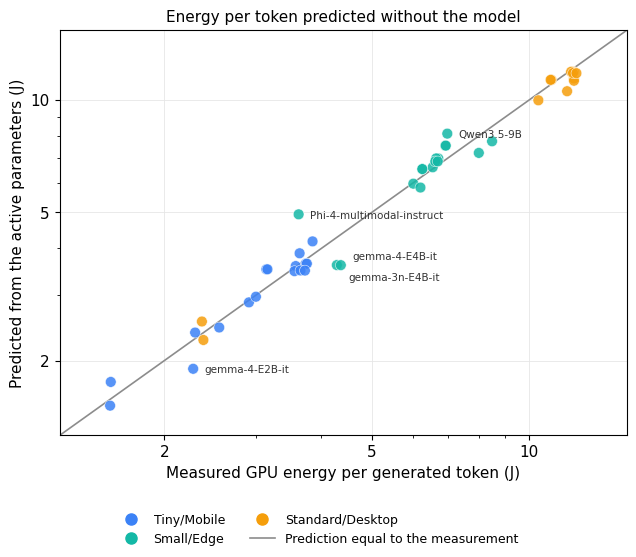

,Leaving the model out,Leaving its family out
Median error (%),4.4,4.8
90th percentile (%),13.5,14.4
Largest error (%),36.4,35.7


In [15]:
def predict_left_out(left_out):
    # Prediction of the models of the mask from a power law fitted to the other models
    scale, exponent, _ = power_law(models.loc[~left_out, "activated_parameters"], models.loc[~left_out, "gpu_joules_per_generated_token"])
    return scale * models.loc[left_out, "activated_parameters"] ** exponent


models["predicted"] = pd.concat([predict_left_out(models.index == index) for index in models.index])
models["predicted_without_family"] = pd.concat([predict_left_out(models["family"] == family) for family in models["family"].unique()])
models["error"] = 100 * (models["predicted"] / models["gpu_joules_per_generated_token"] - 1)
models["error_without_family"] = 100 * (models["predicted_without_family"] / models["gpu_joules_per_generated_token"] - 1)

fig, ax = plt.subplots(figsize=(6.5, 5.6))
limits = [0.8 * models["gpu_joules_per_generated_token"].min(), 1.25 * models["gpu_joules_per_generated_token"].max()]
ax.plot(limits, limits, color="0.55", linewidth=1.2, zorder=1)
ax.scatter(models["gpu_joules_per_generated_token"], models["predicted"], c=models["category"].map(CATEGORY_COLORS), edgecolors="w", **SCATTER_STYLE)
for _, model in models[models["error"].abs() > 15].iterrows():
    name = model["model"].split("/")[-1]
    offset = {"gemma-3n-E4B-it": (8, -11), "gemma-4-E4B-it": (8, 4)}.get(name, (8, -3))
    ax.annotate(name, (model["gpu_joules_per_generated_token"], model["predicted"]), xytext=offset, textcoords="offset points", fontsize=7.5, color="0.2")
ax.set_xscale("log")
ax.set_yscale("log")
plain_log_axis(ax.xaxis)
plain_log_axis(ax.yaxis)
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_xlabel("Measured GPU energy per generated token (J)")
ax.set_ylabel("Predicted from the active parameters (J)")
ax.set_title("Energy per token predicted without the model", fontsize=11)
handles = [Line2D([], [], marker="o", linestyle="", markersize=8, color=color, label=category) for category, color in CATEGORY_COLORS.items()]
handles.append(Line2D([], [], color="0.55", linewidth=1.2, label="Prediction equal to the measurement"))
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.1, 1, 1))
save_chart(fig, "rq3-predicted-energy-per-token")
plt.show()

errors = pd.DataFrame({
    "Leaving the model out": models["error"].abs().describe(percentiles=[0.5, 0.9]),
    "Leaving its family out": models["error_without_family"].abs().describe(percentiles=[0.5, 0.9]),
}).loc[["50%", "90%", "max"]].rename(index={"50%": "Median error (%)", "90%": "90th percentile (%)", "max": "Largest error (%)"})
errors.round(1)

The energy per question is the energy per token multiplied by the generated tokens per question. We measure the share of the variation of each of the three, on a log scale, that is explained by the size of the model (active parameters), by its operating mode, and by both.

In [16]:
def explained(target, *predictors):
    # Share of the variance of the target explained by a linear model on the predictors (R²)
    design = np.column_stack([np.ones(len(target)), *predictors])
    residuals = target - design @ np.linalg.lstsq(design, target, rcond=None)[0]
    return 1 - residuals.var() / target.var()


log_size = np.log(model_runs["activated_parameters"].to_numpy())
is_reasoning = (model_runs["mode"] == "Reasoning").to_numpy().astype(float)
TARGETS = {
    "Energy per generated token": "gpu_joules_per_generated_token",
    "Generated tokens per question": "generated_tokens_per_question",
    "Energy per question": "gpu_joules_per_question",
}
explained_table = pd.DataFrame({
    name: {
        "Size": explained(np.log(model_runs[column].to_numpy()), log_size),
        "Operating mode": explained(np.log(model_runs[column].to_numpy()), is_reasoning),
        "Size and operating mode": explained(np.log(model_runs[column].to_numpy()), log_size, is_reasoning),
    }
    for name, column in TARGETS.items()
}).T
(100 * explained_table).round(1)

,Size,Operating mode,Size and operating mode
Energy per generated token,97.7,0.1,97.7
Generated tokens per question,0.2,82.6,82.6
Energy per question,22.2,67.7,86.5


### 10. Size and Intelligence Efficiency
We compare the instruct runs of the three size categories by the median of their accuracy, of their GPU energy per question and of their correct answers per kJ, over all the releases and over those of 2025 and 2026. We also compute the rank correlation (Spearman) between the active parameters of the instruct runs and their correct answers per kJ.

In [17]:
PERIODS = {"All releases": instruct, "Releases of 2025 and 2026": instruct[instruct["release_date"] >= "2025-01-01"]}
by_size = pd.concat({
    period: runs.groupby("category").agg(
        runs=("model_run", "size"),
        accuracy=("accuracy", "median"),
        gpu_joules_per_generated_token=("gpu_joules_per_generated_token", "median"),
        generated_tokens_per_question=("generated_tokens_per_question", "median"),
        gpu_joules_per_question=("gpu_joules_per_question", "median"),
        correct_answers_per_kj=("correct_answers_per_kj", "median"),
    ).reindex(CATEGORY_ORDER)
    for period, runs in PERIODS.items()
})

size_correlation = instruct["activated_parameters"].corr(instruct["correct_answers_per_kj"], method="spearman")
print(f"Rank correlation between the active parameters and the correct answers per kJ of the instruct runs: {size_correlation:.2f}")

by_size.round({"accuracy": 3, "gpu_joules_per_generated_token": 2, "generated_tokens_per_question": 0, "gpu_joules_per_question": 0, "correct_answers_per_kj": 3})

Rank correlation between the active parameters and the correct answers per kJ of the instruct runs: -0.72


runs  accuracy  \
                          category                           
All releases              Tiny/Mobile         13     0.460   
                          Small/Edge          15     0.509   
                          Standard/Desktop    10     0.595   
Releases of 2025 and 2026 Tiny/Mobile          6     0.609   
                          Small/Edge           6     0.676   
                          Standard/Desktop     3     0.707   

                                            gpu_joules_per_generated_token  \
                          category                                           
All releases              Tiny/Mobile                                 3.14   
                          Small/Edge                                  6.54   
                          Standard/Desktop                           12.00   
Releases of 2025 and 2026 Tiny/Mobile                                 3.64   
                          Small/Edge                                  5.56   
                          Standard/Desktop                           11.04   

                                            generated_tokens_per_question  \
                          category                                          
All releases              Tiny/Mobile                               249.0   
                          Small/Edge                                239.0   
                          Standard/Desktop                          211.0   
Releases of 2025 and 2026 Tiny/Mobile                               542.0   
                          Small/Edge                                447.0   
                          Standard/Desktop                          310.0   

                                            gpu_joules_per_question  \
                          category                                    
All releases              Tiny/Mobile                         752.0   
                          Small/Edge                         1529.0   
                          Standard/Desktop                   2433.0   
Releases of 2025 and 2026 Tiny/Mobile                        1454.0   
                          Small/Edge                         2322.0   
                          Standard/Desktop                   3234.0   

                                            correct_answers_per_kj  
                          category                                  
All releases              Tiny/Mobile                        0.508  
                          Small/Edge                         0.286  
                          Standard/Desktop                   0.220  
Releases of 2025 and 2026 Tiny/Mobile                        0.376  
                          Small/Edge                         0.265  
                          Standard/Desktop                   0.202

### 11. Instruct Responses at the Limit
For the instruct runs with more than 5% of responses at the output limit, we compute the share of the generated tokens that these responses hold, the median and the mean of the generated tokens of a response, and the accuracy of the responses that reached the limit and of those that did not. We also compute, for each subject, the share of responses at the limit in these runs and in the reasoning runs.

In [18]:
limited_runs = at_limit[(at_limit["mode"] == "Instruct") & (at_limit["at_limit"] > 5)]["model_run"]
front_runs = set(pareto_front(model_runs, "gpu_joules_per_question", "accuracy")["model_run"])

rows = []
for run in limited_runs:
    responses = inferences[inferences["model_run"] == run]
    cut = responses["truncated"]
    rows.append({
        "model_run": short_name(run),
        "on_pareto_front": run in front_runs,
        "at_limit": 100 * cut.mean(),
        "tokens_at_limit": 100 * responses.loc[cut, "generated_tokens"].sum() / responses["generated_tokens"].sum(),
        "median_tokens": responses["generated_tokens"].median(),
        "mean_tokens": responses["generated_tokens"].mean(),
        "accuracy_at_limit": 100 * responses.loc[cut, "correct"].mean(),
        "accuracy_finished": 100 * responses.loc[~cut, "correct"].mean(),
    })
limited = pd.DataFrame(rows).sort_values("at_limit", ascending=False).set_index("model_run")

by_subject = pd.DataFrame({
    "Instruct runs above 5%": inferences[inferences["model_run"].isin(limited_runs)].groupby("subject")["truncated"].mean(),
    "Reasoning runs": inferences[inferences["model_run"].isin(reasoning["model_run"])].groupby("subject")["truncated"].mean(),
}).mul(100).sort_values("Instruct runs above 5%", ascending=False)
print("Responses at the output limit by subject (%):")
print(by_subject.round(1).to_string())

limited.round(1)

Responses at the output limit by subject (%):
                  Instruct runs above 5%  Reasoning runs
subject                                                 
engineering                         32.3            49.2
math                                16.9            21.6
physics                             12.5            26.1
chemistry                           10.6            23.9
computer science                     9.2            14.4
economics                            8.8             9.3
law                                  7.9            14.3
business                             7.5            12.8
other                                5.9             9.9
health                               4.0             3.7
philosophy                           3.3             1.8
biology                              3.2             5.2
psychology                           0.8             2.1
history                              0.0             1.1


,on_pareto_front,at_limit,tokens_at_limit,median_tokens,mean_tokens,accuracy_at_limit,accuracy_finished
model_run,,,,,,,
Qwen3.5-4B (I),True,15.1,37.9,510.0,813.5,26.8,82.0
Ministral-3-3B-Instruct-2512-BF16,False,11.0,44.2,198.0,510.6,24.4,65.0
Qwen3-4B-Instruct-2507,True,10.5,33.1,427.0,649.6,30.8,76.9
Qwen3.5-9B (I),True,10.2,31.3,409.0,669.2,31.6,84.7
Ministral-3-8B-Instruct-2512-BF16,False,6.7,29.4,286.5,467.9,24.0,73.2
gemma-4-E4B-it (I),False,5.9,18.8,468.0,645.6,36.4,72.9


### 12. Key Values

In [19]:
print("Power law of the energy per generated token:")
for column, (scale, exponent, r_squared) in fits.items():
    print(f"  {PANELS[column]}: {scale:.2f} J x size ^ {exponent:.2f}, R2 {r_squared:.3f}")
print(f"  prediction without the model: median error {errors.iloc[0, 0]:.1f}%, largest {errors.iloc[2, 0]:.1f}%; without its family: median {errors.iloc[0, 1]:.1f}%, largest {errors.iloc[2, 1]:.1f}%")

print(f"  doubling the active parameters multiplies the energy per token by {2 ** fits['activated_parameters'][1]:.2f}")
largest = models.loc[models["error"].abs().idxmax()]
print(f"  largest error: {largest['model'].split('/')[-1]} ({largest['total_parameters']:g}B parameters, {largest['gpu_joules_per_generated_token']:.2f} J per token)")

print("\nA smaller and a larger model of similar accuracy:")
smaller, larger = values.loc["Qwen/Qwen3-4B-Instruct-2507"], values.loc["Qwen/Qwen3-14B (Instruct Mode)"]
for name, column in {"Accuracy": "accuracy", "Energy per question (J)": "gpu_joules_per_question", "Tokens per question": "generated_tokens_per_question", "Energy per token (J)": "gpu_joules_per_generated_token"}.items():
    print(f"  {name}: Qwen3-4B-Instruct-2507 {smaller[column]:.3f}, Qwen3-14B (I) {larger[column]:.3f}, ratio {smaller[column] / larger[column]:.2f}")

print("\nBest accuracy of the instruct runs by size category:")
for category in CATEGORY_ORDER:
    best = records[category].iloc[-1]
    print(f"  {category}: {best['accuracy']:.3f} ({short_name(best['model_run'])}, {best['release_date'].date()})")

print("\nSparsely activated models against the dense models of their period:")
print(sparse_table.to_string(index=False))
print("\nSparsely activated models against the earlier dense models of their family:")
print(family_table.to_string(index=False))
print("\nSparsely activated models and the Pareto front:")
print(sparse_front.to_string(index=False))

print("\nPrecision (16-bit against 8-bit):")
print(precision_table[["Energy per token (16-bit ÷ 8-bit)", "Energy per question (16-bit ÷ 8-bit)", "Accuracy difference (points)", "McNemar p"]].to_string())

print("\nOperating mode, reasoning against instruct, per pair:")
print(mode_table[["pair", "as_recorded", "p_value", "strict", "finished", "finished_p_value", "common", "energy_ratio", "tokens_ratio", "efficiency_ratio"]].round(3).to_string(index=False))

print("\nVariation explained (%):")
print((100 * explained_table).round(1).to_string())

Power law of the energy per generated token:
  Total parameters (billions): 1.15 J x size ^ 0.79, R2 0.666
  Active parameters (billions): 1.03 J x size ^ 0.91, R2 0.980
  prediction without the model: median error 4.4%, largest 36.4%; without its family: median 4.8%, largest 35.7%
  doubling the active parameters multiplies the energy per token by 1.88
  largest error: Phi-4-multimodal-instruct (5.57B parameters, 3.62 J per token)

A smaller and a larger model of similar accuracy:
  Accuracy: Qwen3-4B-Instruct-2507 0.723, Qwen3-14B (I) 0.707, ratio 1.02
  Energy per question (J): Qwen3-4B-Instruct-2507 2424.563, Qwen3-14B (I) 2131.362, ratio 1.14
  Tokens per question: Qwen3-4B-Instruct-2507 649.559, Qwen3-14B (I) 174.167, ratio 3.73
  Energy per token (J): Qwen3-4B-Instruct-2507 3.733, Qwen3-14B (I) 12.237, ratio 0.31

Best accuracy of the instruct runs by size category:
  Tiny/Mobile: 0.737 (Qwen3.5-4B (I), 2026-02-27)
  Small/Edge: 0.793 (Qwen3.5-9B (I), 2026-02-27)
  Standard/Desk